# Лабораторная работа №1. Методы улучшения контраста изображений

Курс «Машинное зрение», **вариант 1-08**. Исходное изображение должно лежать рядом с ноутбуком: `requirements/image_v1-08.jpg`; рисунки для отчёта сохраняются в `figures/`.

Формулы метрик — по лекции 2 курса (А.Г. Трофимов, НИЯУ МИФИ). Все вычисления реализованы вручную на numpy и сверены со scikit-image.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.axes import Axes
from matplotlib.colors import LogNorm
from numpy.typing import NDArray
from skimage import io
from skimage.feature import graycomatrix, graycoprops

P = 256  # число градаций яркости (8 бит)
BT601 = np.array([0.299, 0.587, 0.114])  # веса R, G, B для перевода в серое
IMAGE_PATH = Path("requirements/image_v1-08.jpg")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

## Общие функции

Используются во всех пунктах лабы.

In [2]:
def to_gray(img: NDArray[np.uint8]) -> NDArray[np.uint8]:
    """Переводит RGB-изображение в градации серого по стандарту BT.601.

    Args:
        img: NDArray[np.uint8] - Изображение формы (M, N, 3) или уже серое (M, N).

    Returns:
        NDArray[np.uint8] - Серое изображение формы (M, N) с яркостями [0; 255].

    Raises:
        ValueError: если у цветного изображения не 3 канала.

    """
    if img.ndim == 2:
        return img
    if img.shape[-1] != 3:
        msg = f"Ожидалось 3 канала (RGB), получено {img.shape[-1]}"
        raise ValueError(msg)
    return np.round(img @ BT601).astype(np.uint8)


def glcm(img: NDArray[np.uint8], d: int, alpha: int) -> NDArray[np.float64]:
    """Считает нормированную матрицу Харалика (GLCM) размера P × P.

    Элемент g[p, q] — доля пар соседних пикселей, где у пикселя яркость p,
    а у соседа на расстоянии d в направлении alpha — яркость q.

    Args:
        img: NDArray[np.uint8] - Серое изображение формы (M, N).
        d: int - Расстояние до соседа в пикселях, не меньше 1.
        alpha: int - Направление в градусах: 0 — сосед справа, 90 — сосед снизу.

    Returns:
        NDArray[np.float64] - Матрица формы (P, P), сумма элементов равна 1.

    Raises:
        ValueError: если alpha не 0 и не 90 или d вне [1; размер изображения).

    """
    if d < 1:
        msg = f"Расстояние d должно быть >= 1, получено {d}"
        raise ValueError(msg)
    if alpha == 0:
        ref, nbr = img[:, :-d], img[:, d:]
    elif alpha == 90:
        ref, nbr = img[:-d, :], img[d:, :]
    else:
        msg = f"Поддерживаются углы 0 и 90, получено {alpha}"
        raise ValueError(msg)
    if ref.size == 0:
        msg = f"Расстояние d={d} не меньше размера изображения {img.shape}"
        raise ValueError(msg)
    g = np.zeros((P, P))
    np.add.at(g, (ref.ravel(), nbr.ravel()), 1)
    return g / g.sum()


def haralick_contrast(g: NDArray[np.float64]) -> float:
    """Считает контраст Харалика: сумму (p - q)² · g[p, q] по всей матрице.

    Args:
        g: NDArray[np.float64] - Нормированная матрица Харалика.

    Returns:
        float - Контраст Харалика.

    """
    p, q = np.indices(g.shape)
    return float(((p - q) ** 2 * g).sum())


def contrast_stats(img: NDArray[np.uint8]) -> dict[str, float]:
    """Считает статистические характеристики и контрасты серого изображения.

    Формулы — по лекции 2 (А.Г. Трофимов). Экстремумы приводятся к int,
    иначе сумма a_max + a_min переполнит uint8.

    Args:
        img: NDArray[np.uint8] - Серое изображение формы (M, N).

    Returns:
        dict[str, float] - Характеристики: a_min, a_max, range_usage_pct,
            n_levels, mean, var, michelson, global, rms, haralick (d=1, alpha=0).

    """
    a_min, a_max = int(img.min()), int(img.max())
    width = a_max - a_min
    return {
        "a_min": a_min,
        "a_max": a_max,
        "range_usage_pct": width / (P - 1) * 100,
        "n_levels": len(np.unique(img)),
        "mean": float(img.mean()),
        "var": float(img.var()),
        "michelson": width / (a_max + a_min) if a_max + a_min else 0.0,
        "global": width / (P - 1),
        "rms": float(img.std()),
        "haralick": haralick_contrast(glcm(img, 1, 0)),
    }


def show_glcm(ax: Axes, g: NDArray[np.float64], title: str) -> None:
    """Рисует матрицу Харалика в логарифмической шкале.

    Нулевые элементы закрашиваются чёрным, как на слайдах лекции.

    Args:
        ax: Axes - Оси matplotlib, на которых рисовать.
        g: NDArray[np.float64] - Нормированная матрица Харалика.
        title: str - Заголовок графика.

    """
    cmap = plt.get_cmap("magma").with_extremes(bad="black")
    image = ax.imshow(np.ma.masked_equal(g, 0), cmap=cmap, norm=LogNorm())
    ax.set_title(title)
    ax.set_xlabel("q — яркость соседа")
    ax.set_ylabel("p — яркость пикселя")
    ax.figure.colorbar(image, ax=ax, label="доля пар $g_{pq}$ (лог. шкала)")

## 1. Загрузка и визуализация изображения

### 1.a) Числовые характеристики изображения

In [3]:
rgb = io.imread(IMAGE_PATH)
height, width, channels = rgb.shape
bits = rgb.dtype.itemsize * 8
display(
    Markdown(
        "| Размерность изображения | Число цветовых каналов | Яркостное разрешение |\n"
        "|:---:|:---:|:---:|\n"
        f"| {width} × {height} пикс. (ширина × высота) | {channels} (RGB) "
        f"| {bits} бит на канал ({2**bits} градаций, `{rgb.dtype}`) |"
    )
)

| Размерность изображения | Число цветовых каналов | Яркостное разрешение |
|:---:|:---:|:---:|
| 702 × 599 пикс. (ширина × высота) | 3 (RGB) | 8 бит на канал (256 градаций, `uint8`) |

### 1.б) Перевод в градации серого

Изображение цветное (3 канала) → приводим к одному каналу по стандарту BT.601 (как `rgb2gray` в MATLAB):

$$Y = 0.299R + 0.587G + 0.114B, \quad Y \in [0; 255]$$

Зелёный имеет наибольший вес, потому что глаз наиболее чувствителен к нему.

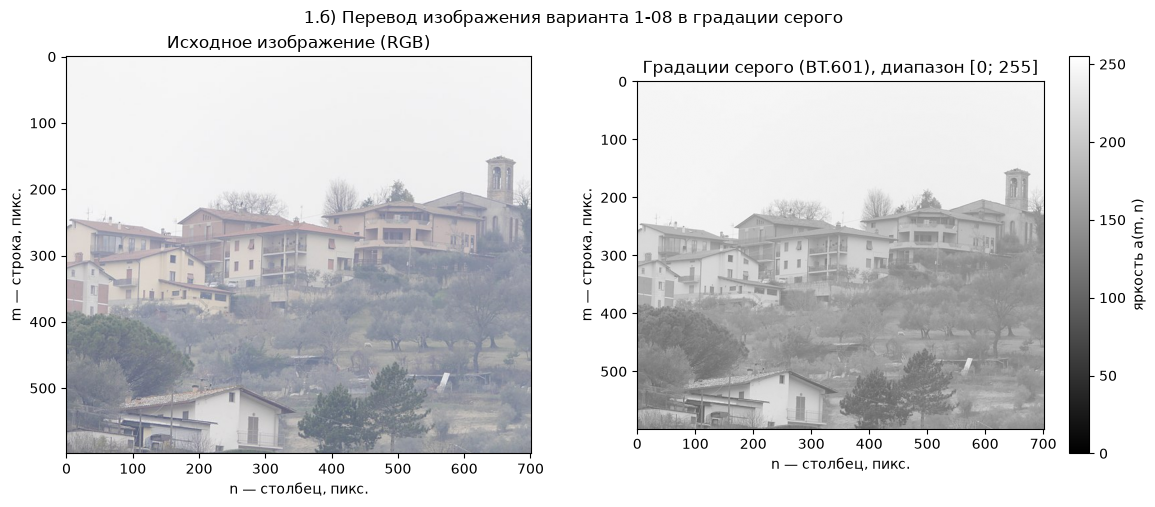

In [4]:
gray = to_gray(rgb)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb)
axes[0].set_title("Исходное изображение (RGB)")
# vmin/vmax обязательны: иначе matplotlib сам растянет контраст и исказит картину
image = axes[1].imshow(gray, cmap="gray", vmin=0, vmax=P - 1)
axes[1].set_title("Градации серого (BT.601), диапазон [0; 255]")
fig.colorbar(image, ax=axes[1], label="яркость a(m, n)")
for ax in axes:
    ax.set_xlabel("n — столбец, пикс.")
    ax.set_ylabel("m — строка, пикс.")
fig.suptitle("1.б) Перевод изображения варианта 1-08 в градации серого")
fig.tight_layout()
fig.savefig(FIGURES / "01b_gray.png", dpi=150)
plt.show()

### 1.в) Статистические характеристики изображения

In [5]:
s = contrast_stats(gray)
display(
    Markdown(
        "| Возможный диапазон яркостей | Динамический диапазон "
        "| % использования яркостного диапазона | Число различных яркостей |\n"
        "|:---:|:---:|:---:|:---:|\n"
        f"| [0; {P - 1}] | [{s['a_min']}; {s['a_max']}] "
        f"| {s['range_usage_pct']:.1f}% | {s['n_levels']} |"
    )
)

| Возможный диапазон яркостей | Динамический диапазон | % использования яркостного диапазона | Число различных яркостей |
|:---:|:---:|:---:|:---:|
| [0; 255] | [80; 255] | 68.6% | 172 |

In [6]:
rows = [
    (
        "Динамический диапазон",
        r"$[a_{min};\ a_{max}]$",
        f"[{s['a_min']}; {s['a_max']}]",
    ),
    (
        "% использования яркостного диапазона",
        r"$\frac{a_{max}-a_{min}}{P-1}\cdot 100\%$",
        f"{s['range_usage_pct']:.2f}%",
    ),
    ("Число различных яркостей", r"$\#\{a(m,n)\}$", f"{s['n_levels']}"),
    (
        "Средняя яркость",
        r"$\bar a = \frac{1}{MN}\sum_{m,n} a(m,n)$",
        f"{s['mean']:.2f}",
    ),
    (
        "Дисперсия яркости",
        r"$D[a] = \frac{1}{MN}\sum_{m,n} (a(m,n)-\bar a)^2$",
        f"{s['var']:.2f}",
    ),
    (
        "Контраст Михельсона",
        r"$C_{Mich} = \frac{a_{max}-a_{min}}{a_{max}+a_{min}}$",
        f"{s['michelson']:.4f}",
    ),
    (
        "Глобальный контраст",
        r"$C_g = \frac{a_{max}-a_{min}}{P-1}$",
        f"{s['global']:.4f}",
    ),
    (
        "Среднеквадратический контраст",
        r"$C_{rms} = \sigma_a = \sqrt{D[a]}$",
        f"{s['rms']:.2f}",
    ),
    (
        r"Контраст Харалика ($d=1,\ \alpha=0^\circ$)",
        r"$C_{GLCM} = \sum_{p,q} (p-q)^2\, g_{pq}$",
        f"{s['haralick']:.2f}",
    ),
]
display(
    Markdown(
        "| Характеристика | Формула | Значение |\n|:---|:---:|:---:|\n"
        + "\n".join(
            f"| {name} | {formula} | {value} |" for name, formula, value in rows
        )
    )
)

| Характеристика | Формула | Значение |
|:---|:---:|:---:|
| Динамический диапазон | $[a_{min};\ a_{max}]$ | [80; 255] |
| % использования яркостного диапазона | $\frac{a_{max}-a_{min}}{P-1}\cdot 100\%$ | 68.63% |
| Число различных яркостей | $\#\{a(m,n)\}$ | 172 |
| Средняя яркость | $\bar a = \frac{1}{MN}\sum_{m,n} a(m,n)$ | 191.63 |
| Дисперсия яркости | $D[a] = \frac{1}{MN}\sum_{m,n} (a(m,n)-\bar a)^2$ | 1955.04 |
| Контраст Михельсона | $C_{Mich} = \frac{a_{max}-a_{min}}{a_{max}+a_{min}}$ | 0.5224 |
| Глобальный контраст | $C_g = \frac{a_{max}-a_{min}}{P-1}$ | 0.6863 |
| Среднеквадратический контраст | $C_{rms} = \sigma_a = \sqrt{D[a]}$ | 44.22 |
| Контраст Харалика ($d=1,\ \alpha=0^\circ$) | $C_{GLCM} = \sum_{p,q} (p-q)^2\, g_{pq}$ | 45.43 |

#### Матрица Харалика

Матрица Харалика $G_{\alpha,d}$ размера $P \times P$: элемент $g_{pq}$ — доля пар пикселей, где у пикселя яркость $p$, а у соседа на расстоянии $d$ в направлении $\alpha$ — яркость $q$. $\alpha = 0^\circ$ — сосед справа, $\alpha = 90^\circ$ — сосед по вертикали (соглашение scikit-image; на контраст направление «вверх/вниз» не влияет, т.к. $(p-q)^2 = (q-p)^2$).

Контраст Харалика $C_{GLCM} = \sum_{p,q}(p-q)^2 g_{pq}$ при $\sum g_{pq} = 1$. На слайде 29 лекции даны два варианта с множителем $\frac{1}{P^2}$ — с $|p-q|$ и с $(p-q)^2$. Но при $\sum g_{pq} = 1$ с этим множителем контраст всегда меньше 1 (ведь $(p-q)^2 \le (P-1)^2 < P^2$), а вариант $\sum |p-q|\,g_{pq}$ не превышает $P - 1 = 255$. Значение 598.9 из примера на слайде 30 возможно только для $\sum (p-q)^2 g_{pq}$ без множителя — используем её (так же считают `graycoprops` в scikit-image и MATLAB). Матрицы показаны в логарифмической шкале (значения различаются на порядки), нули — чёрным.

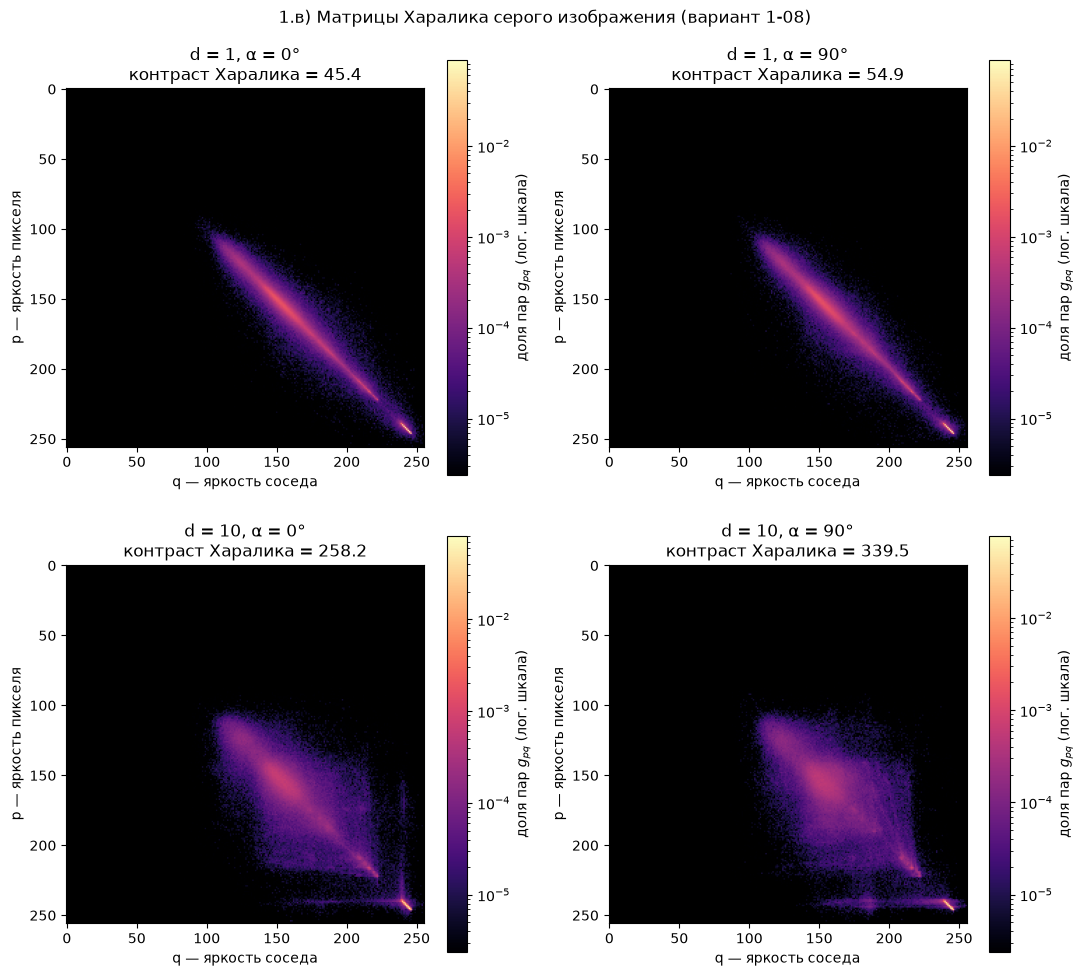

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for row, d in enumerate((1, 10)):
    for col, alpha in enumerate((0, 90)):
        g = glcm(gray, d, alpha)
        show_glcm(
            axes[row, col],
            g,
            f"d = {d}, α = {alpha}°\nконтраст Харалика = {haralick_contrast(g):.1f}",
        )
fig.suptitle("1.в) Матрицы Харалика серого изображения (вариант 1-08)")
fig.tight_layout()
fig.savefig(FIGURES / "01c_glcm.png", dpi=150)
plt.show()

In [8]:
for d in (1, 10):
    for alpha in (0, 90):
        ours = glcm(gray, d, alpha)
        ref = graycomatrix(gray, [d], [np.deg2rad(alpha)], levels=P, normed=True)
        assert np.allclose(ours, ref[:, :, 0, 0])
        assert np.isclose(haralick_contrast(ours), graycoprops(ref, "contrast")[0, 0])
print("Матрицы и контраст Харалика совпадают со scikit-image для всех d и α")

Матрицы и контраст Харалика совпадают со scikit-image для всех d и α


### Выводы по пункту 1

- Изображение 702 × 599, 3 канала, 8 бит на канал. После перевода в серое яркости лежат в [80; 255]: тёмная треть шкалы (0–79) не используется совсем — туман добавляет рассеянный свет и «поднимает» самые тёмные точки.
- Средняя яркость 191.6 — изображение светлое; σ = 44.2 — разброс яркостей умеренный. Внутри динамического диапазона используются почти все уровни (172 из 176).
- Контраст Михельсона (0.52) и глобальный контраст (0.69) зависят только от двух крайних яркостей, а их задают единичные пиксели: a_max = 255 — у 10 пикселей-выбросов на границах объектов (само небо не ярче 249), a_min = 80 — у одного пикселя. 98 % пикселей лежат в [114; 246] — это лишь ~52 % шкалы, а не 69 %. Поэтому эти метрики плохо описывают «мыльность» картинки; среднеквадратический контраст учитывает все пиксели.
- Контраст Харалика при d = 1 мал (45 по горизонтали, 55 по вертикали): соседние пиксели почти одинаковы, матрица прижата к диагонали. При d = 10 он растёт примерно в 6 раз (258 и 340), матрица «расплывается»: далёкие пиксели чаще принадлежат разным объектам.
- Яркое пятно в правом нижнем углу матриц (≈ 240–250) — небо: большая однородная светлая область. При d = 10 от него отходят горизонтальная и вертикальная «полосы» (p или q ≈ 240) — это пары «небо — дом/дерево» на линии горизонта.
- По вертикали контраст выше, чем по горизонтали: в сцене преобладают горизонтальные структуры (горизонт, ряды крыш, этажи, ярусы холма), поэтому вдоль строки яркость меняется медленнее, чем поперёк.
- Итог: изображение низкоконтрастное и использует ~69% шкалы — его нужно контрастировать (пункт 2).